# MonReader — 01 Data Audit and Historical Split Design

> **Submission status:** reproducible historical notebook.  
> **Scientific authority:** historical pre-V2 evidence; the current V2 protocol on `main` remains authoritative.

## Purpose

Establish the dataset structure, source-video dependence, and the historical O/S/T/ST evaluation regimes before any model comparison.

## How to read / rerun

- **Report mode (default):** uses committed result snapshots and embedded verified figures; no dataset, GPU, or W&B account is required.
- **Local reproduction mode:** set `MONREADER_DATA_ROOT` to a local dataset copy and rerun the relevant data-audit code.
- All paths are repository-relative; no machine-specific Windows path is required.

## Notebook flow

**Data integrity → source/video audit → frozen historical split definitions → representative visual audit → modelling implications**

---

In [ ]:
from pathlib import Path
import sys

# Portable repository discovery: no machine-specific path assumptions.
HERE = Path.cwd().resolve()
REPO_ROOT = next(
    (p for p in [HERE, *HERE.parents] if (p / "submission" / "results").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Run this notebook from inside a clone of the MonReader repository "
        "or set MONREADER_REPO_ROOT."
    )

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from submission.src.repro import (
    load_local_env,
    load_snapshot,
    display_snapshot,
    display_figure,
    figures_dir,
    data_root,
)

load_local_env()

print(f"Repository root: {REPO_ROOT}")
print(f"Committed results: {REPO_ROOT / 'submission' / 'results'}")
print(f"Committed figures: {figures_dir()}")
print(
    "Optional local data root:",
    data_root() or "not configured — report mode remains fully reviewable",
)


## Reproducibility contract

The committed CSVs and figures under `submission/results/` and `submission/assets/` are **snapshots of the successful notebook outputs**. They allow a reviewer to inspect the verified results immediately.

To rerun data-dependent cells on another machine, set:

```bash
MONREADER_DATA_ROOT=/path/to/extracted/monreader/data
```

The raw dataset is intentionally not committed to GitHub.

In [ ]:
summary = load_snapshot("dataset_regime_summary.csv")
summary

## Frozen historical split summary

| regime   |   train_images |   validation_images |   context_unseen_early_images |   test_images |   total_images |   unique_source_videos |   test_source_videos |   test_sources_also_in_development |
|:---------|---------------:|--------------------:|------------------------------:|--------------:|---------------:|-----------------------:|---------------------:|-----------------------------------:|
| O        |           2152 |                 240 |                             0 |           597 |           2989 |                    117 |                  115 |                                115 |
| S        |           2147 |                 232 |                             0 |           610 |           2989 |                    117 |                   24 |                                  0 |
| T        |           2387 |                 301 |                             0 |           301 |           2989 |                    117 |                  117 |                                117 |
| ST       |           1904 |                 475 |                           489 |           121 |           2989 |                    117 |                   24 |                                  0 |

> Snapshot source: `submission/results/dataset_regime_summary.csv`


### Reading the table

The historical dataset contained **2,989 frames from 117 source videos**. The O regime is highly source-joint: 115 test source videos also appear in development. By construction, the S and ST test sources do not appear in development. T keeps known source videos but evaluates later frames.

These regimes therefore answer different questions and should not be treated as a single leaderboard.

## Representative data audit

The following figures are the actual successful outputs extracted from the completed notebook export.

### Representative images

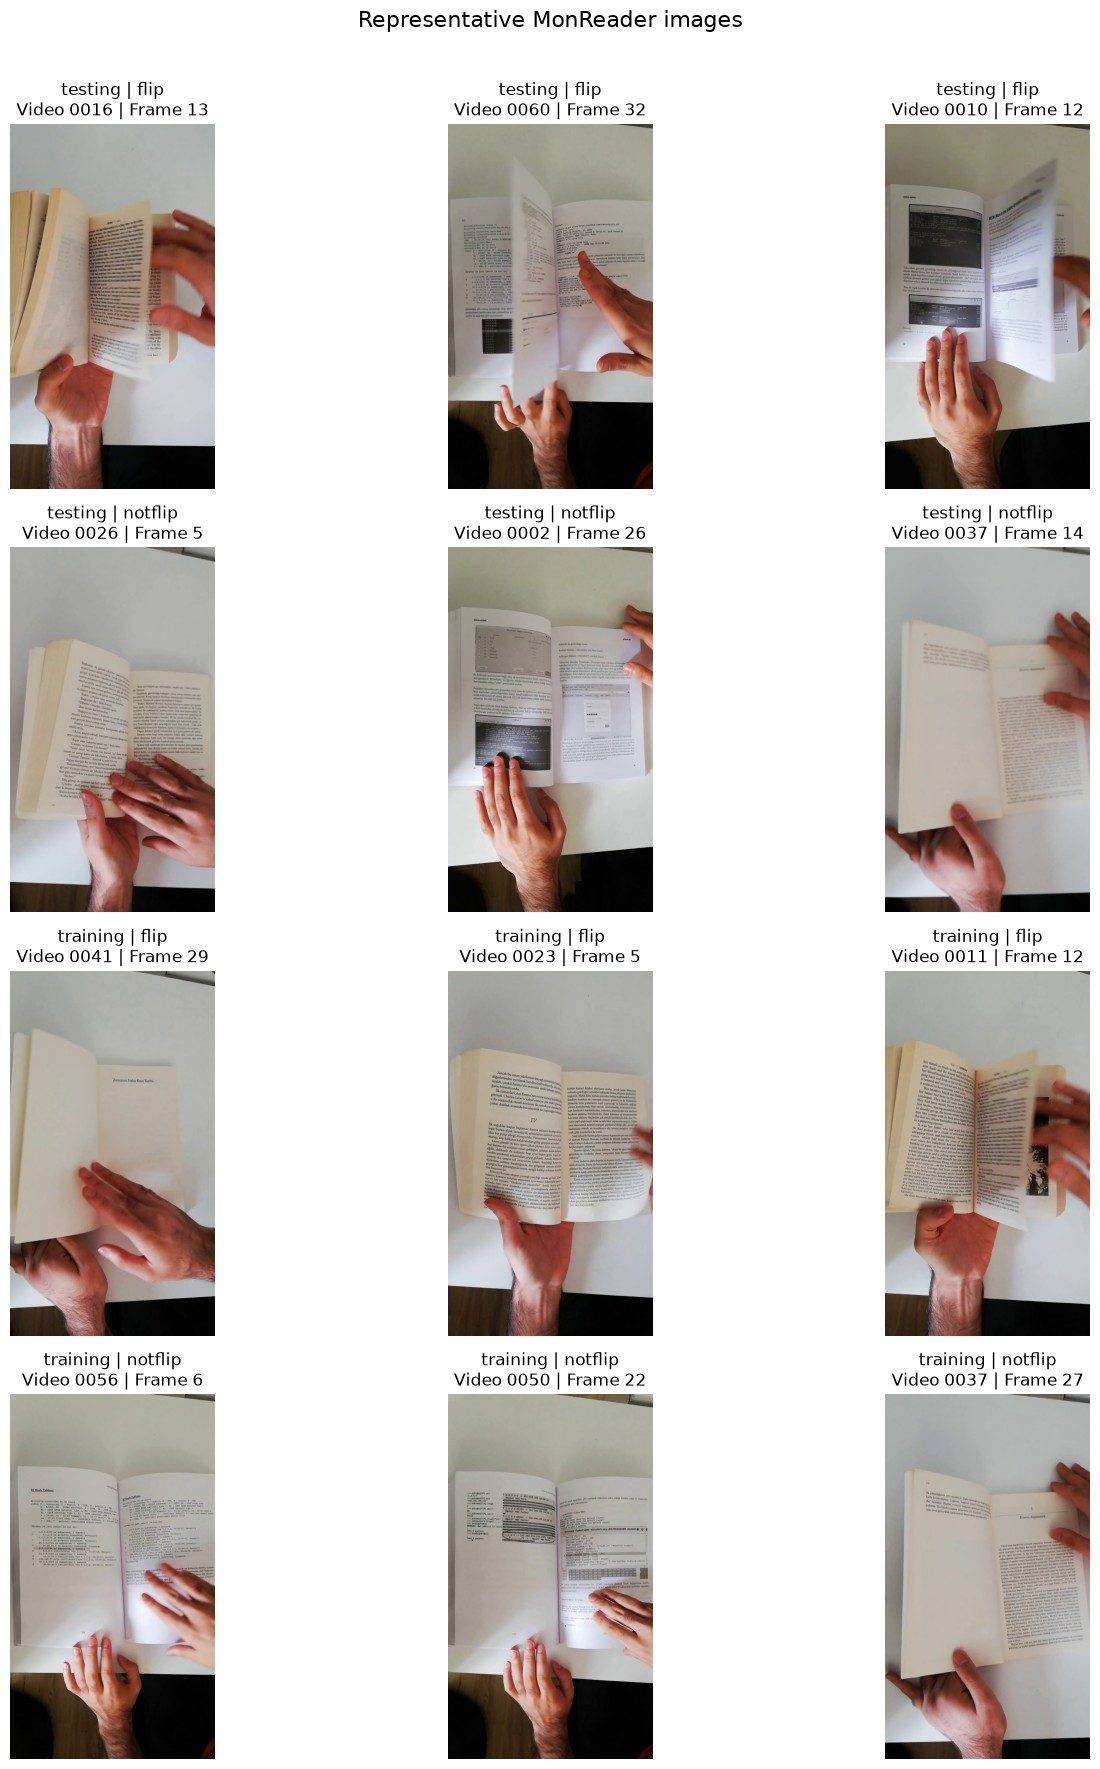

### Chronological examples within videos

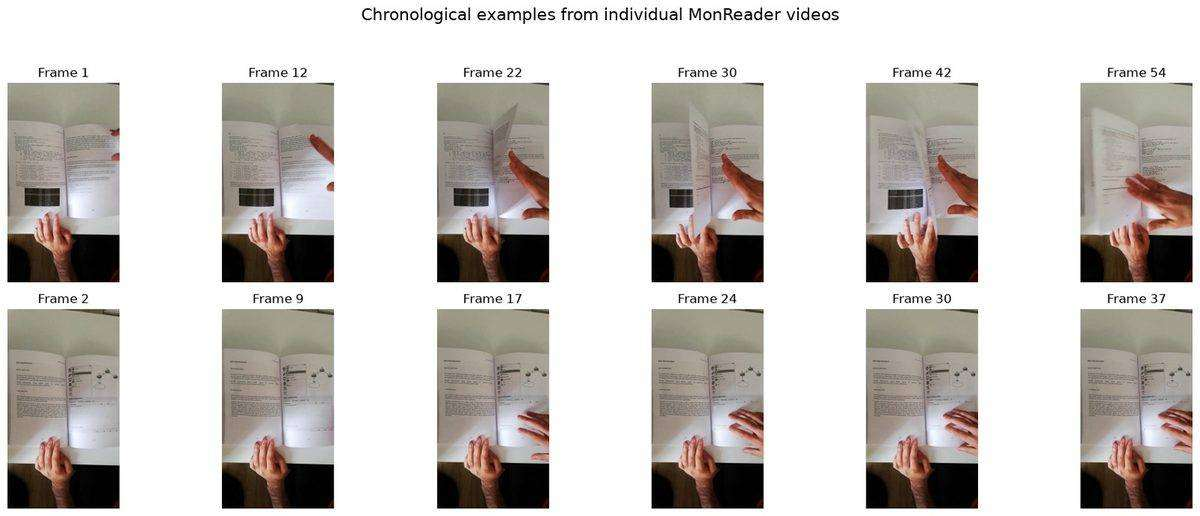

### RGB variability audit

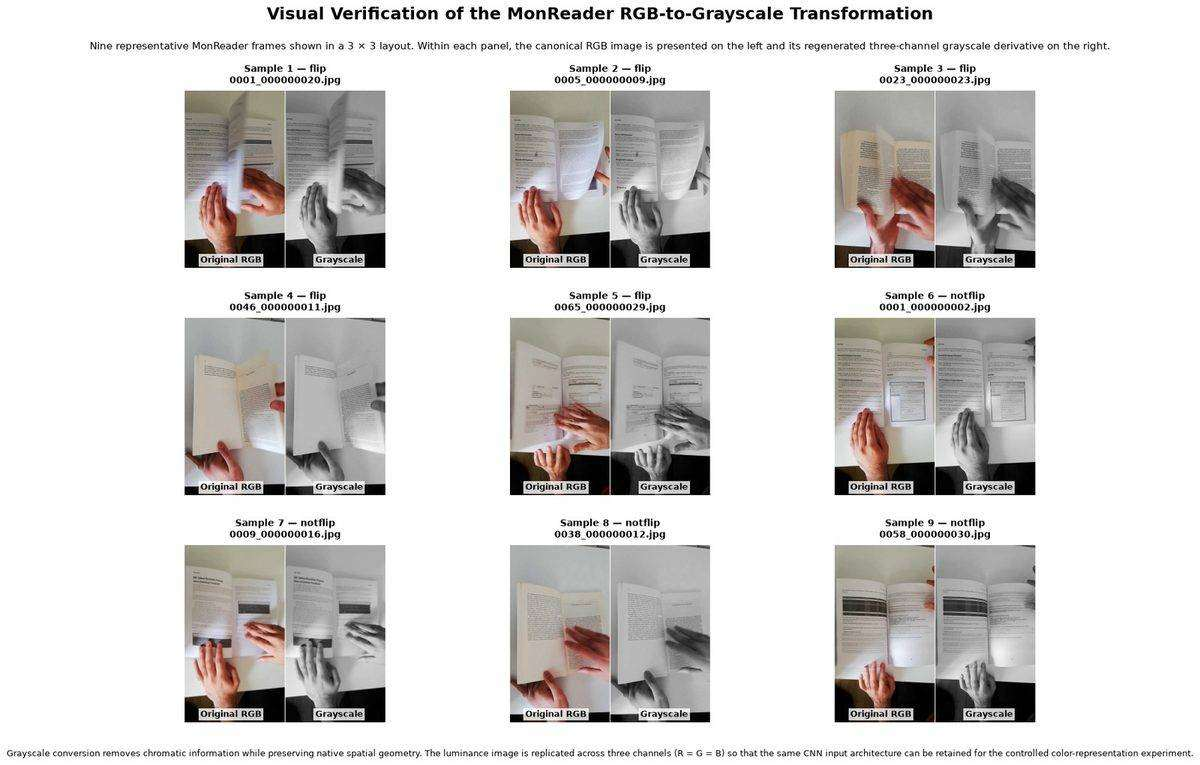


<details>
<summary><strong>Full source-video visual audit (15 panels)</strong></summary>

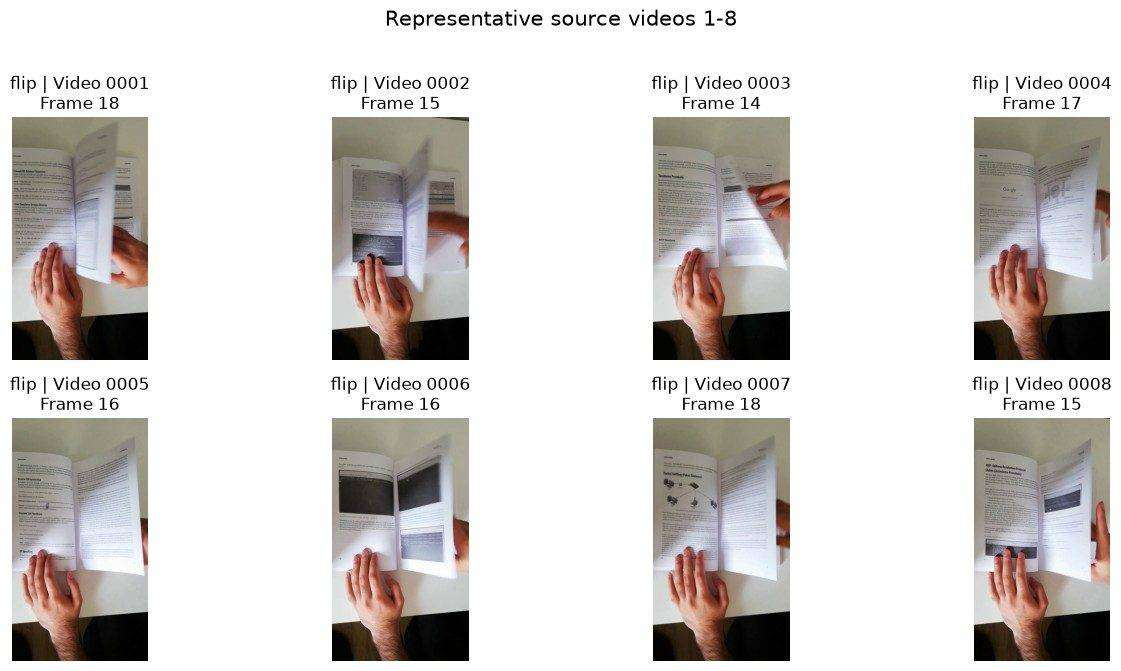

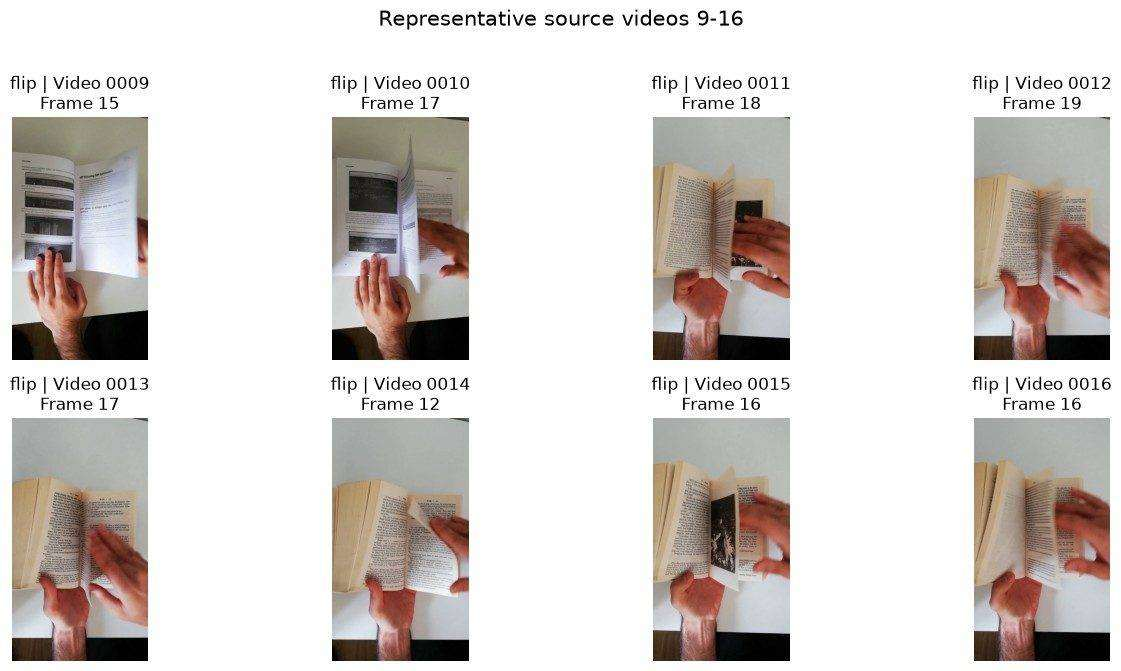

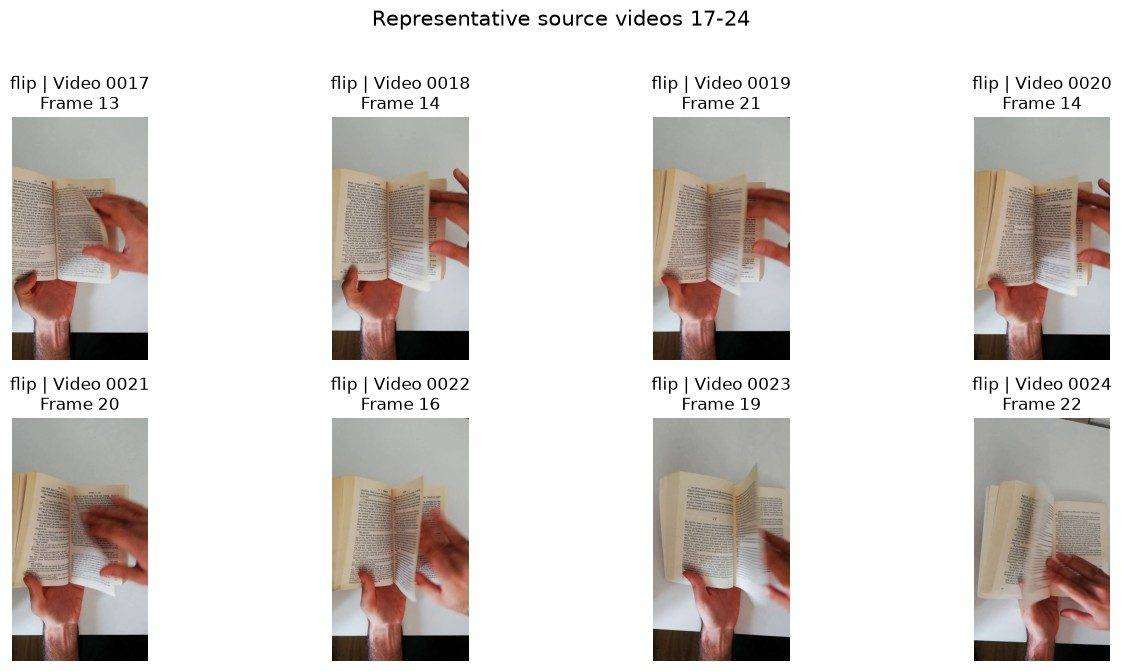

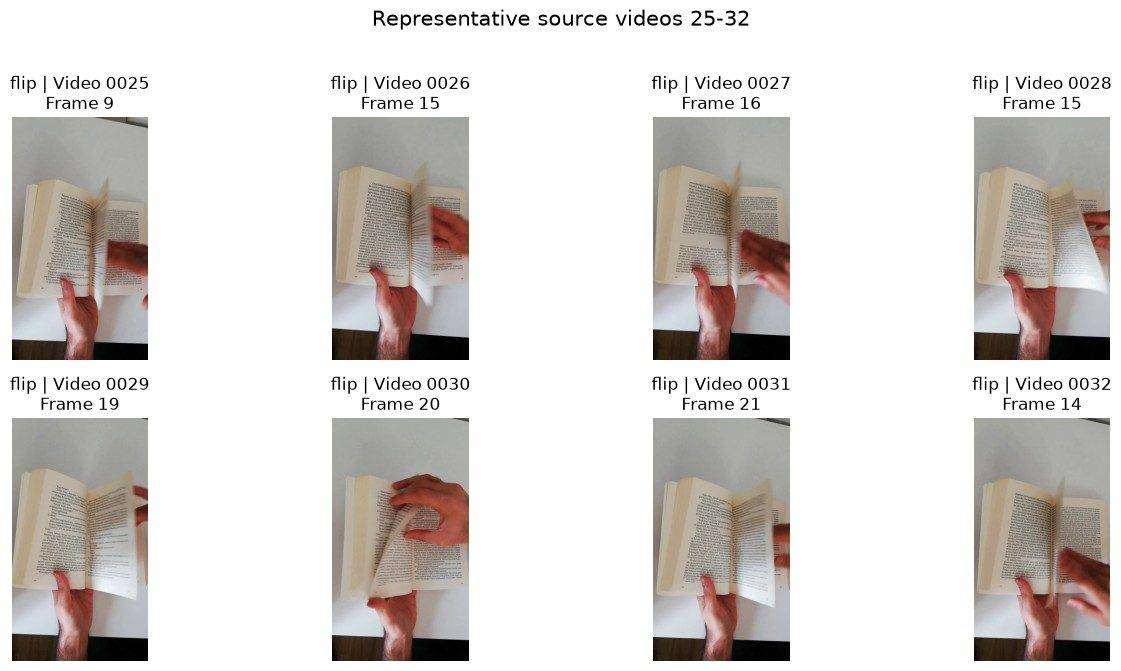

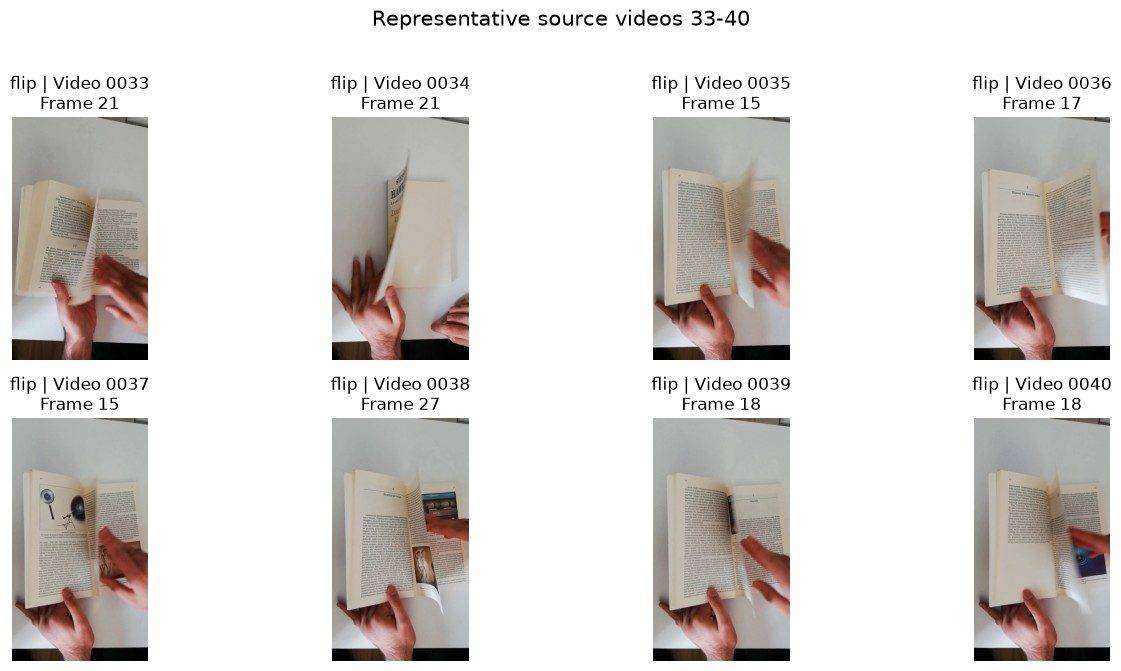

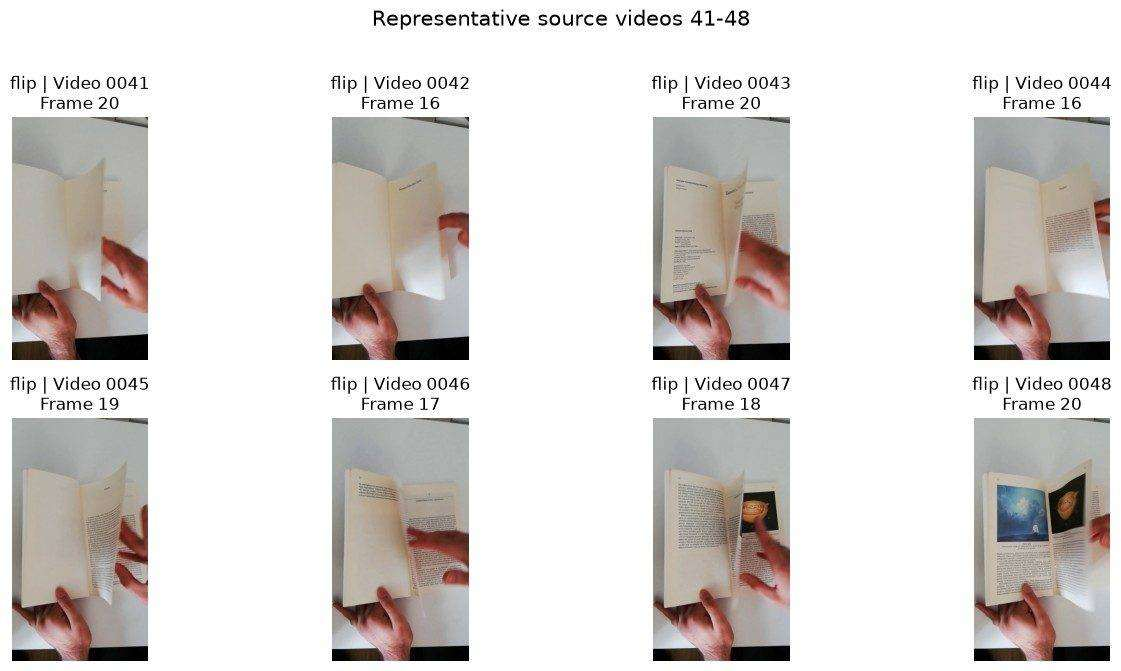

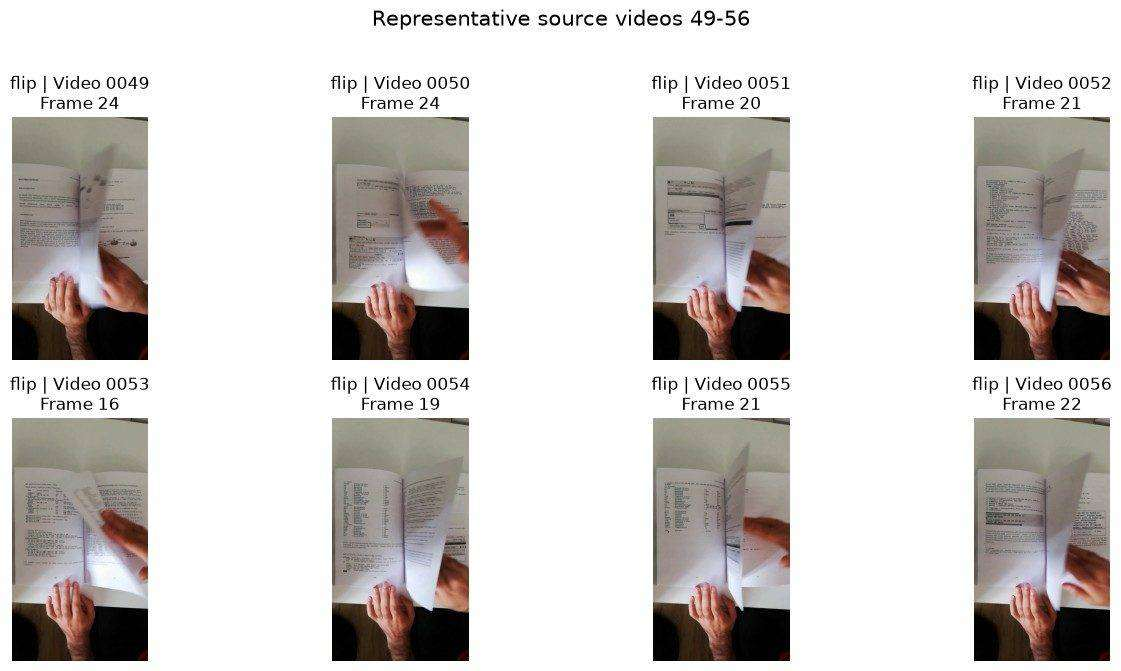

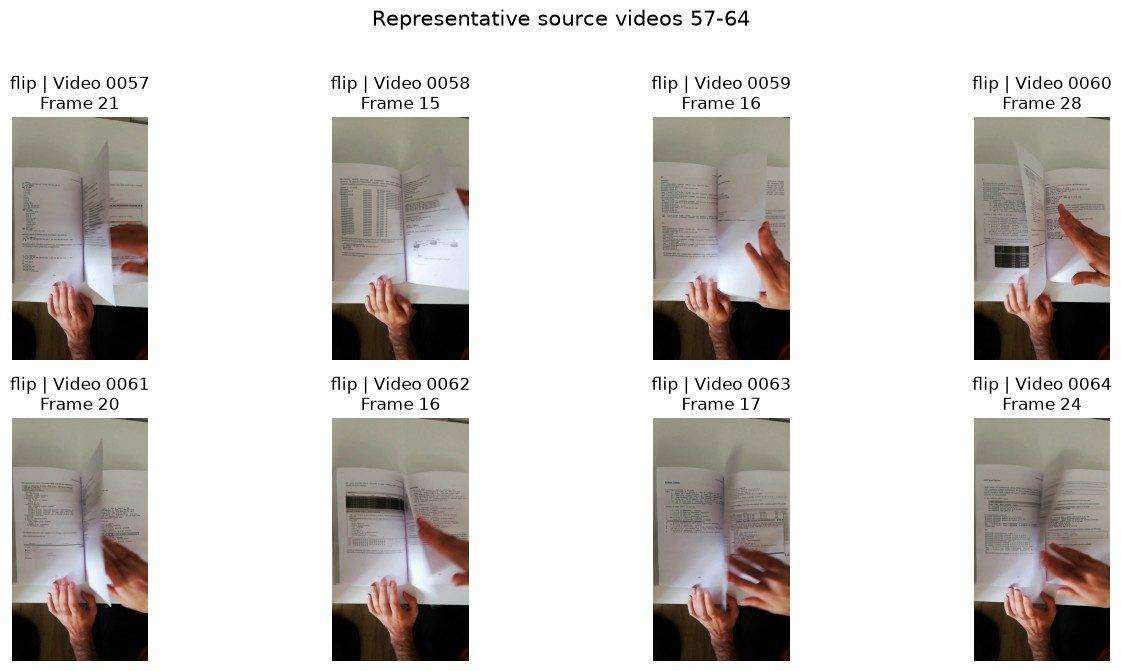

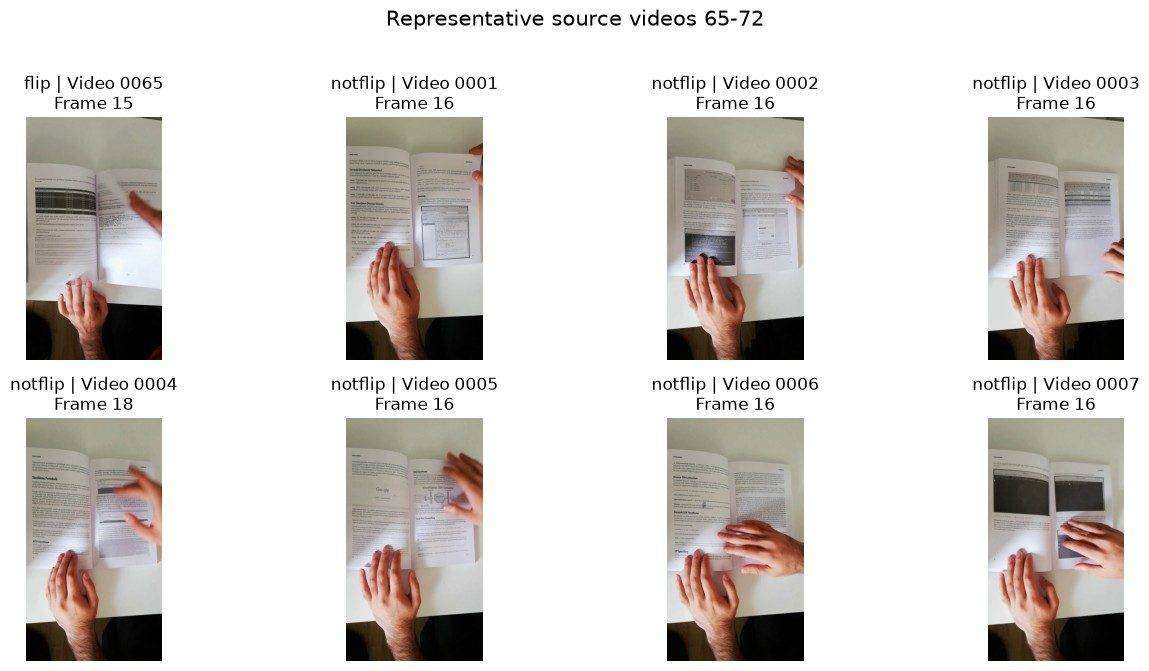

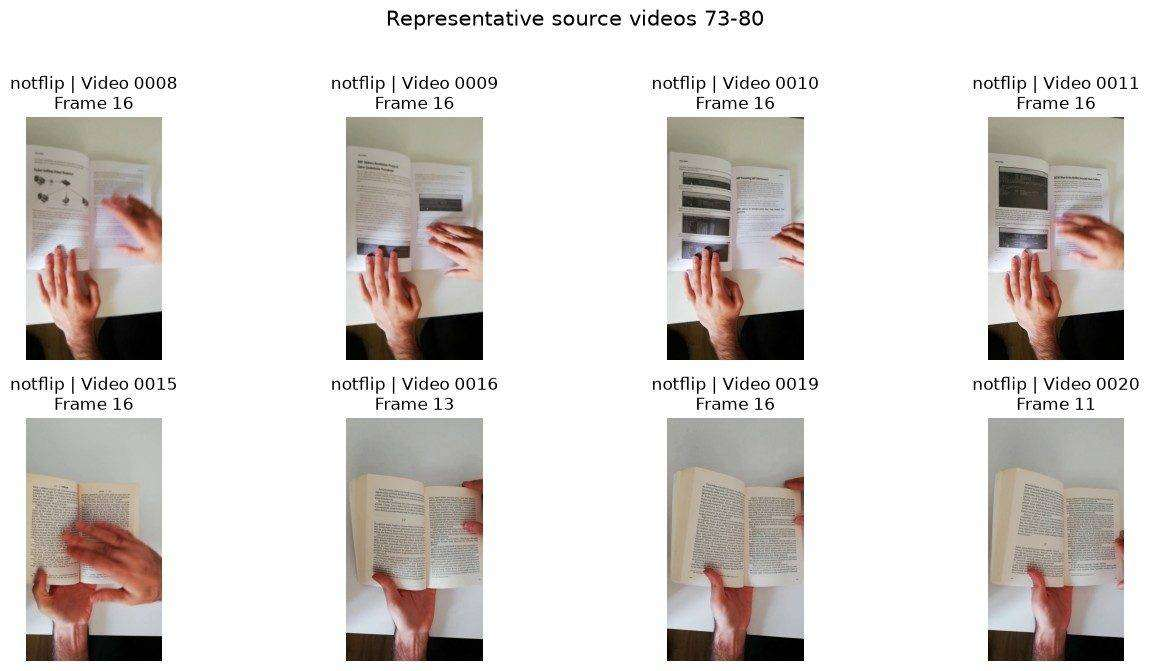

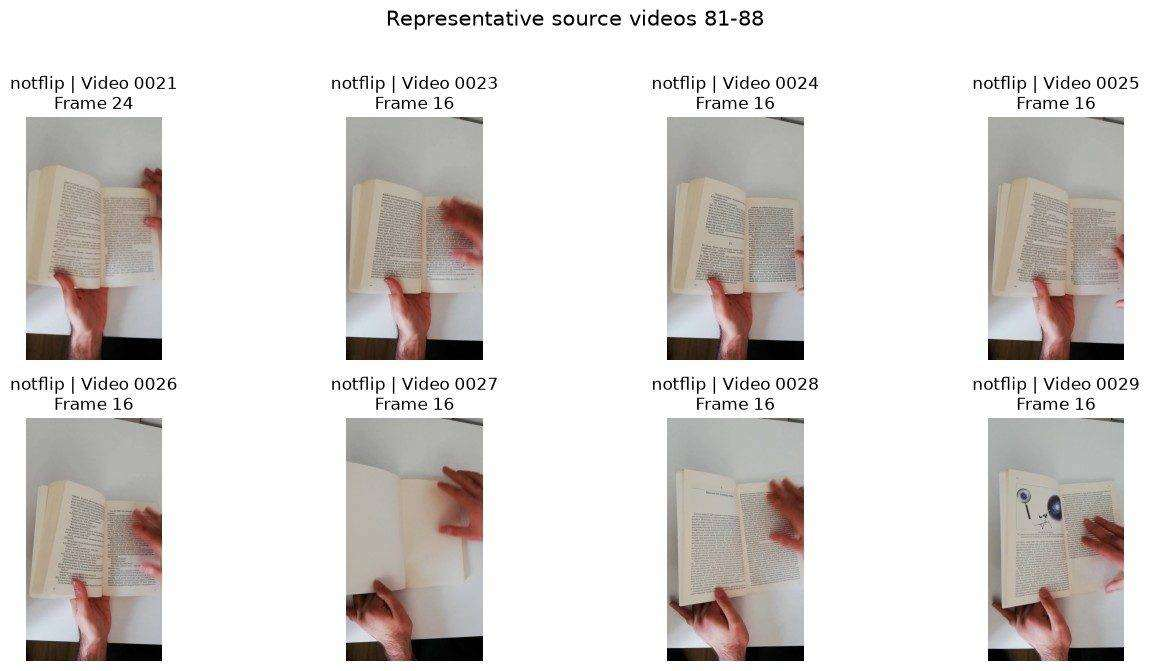

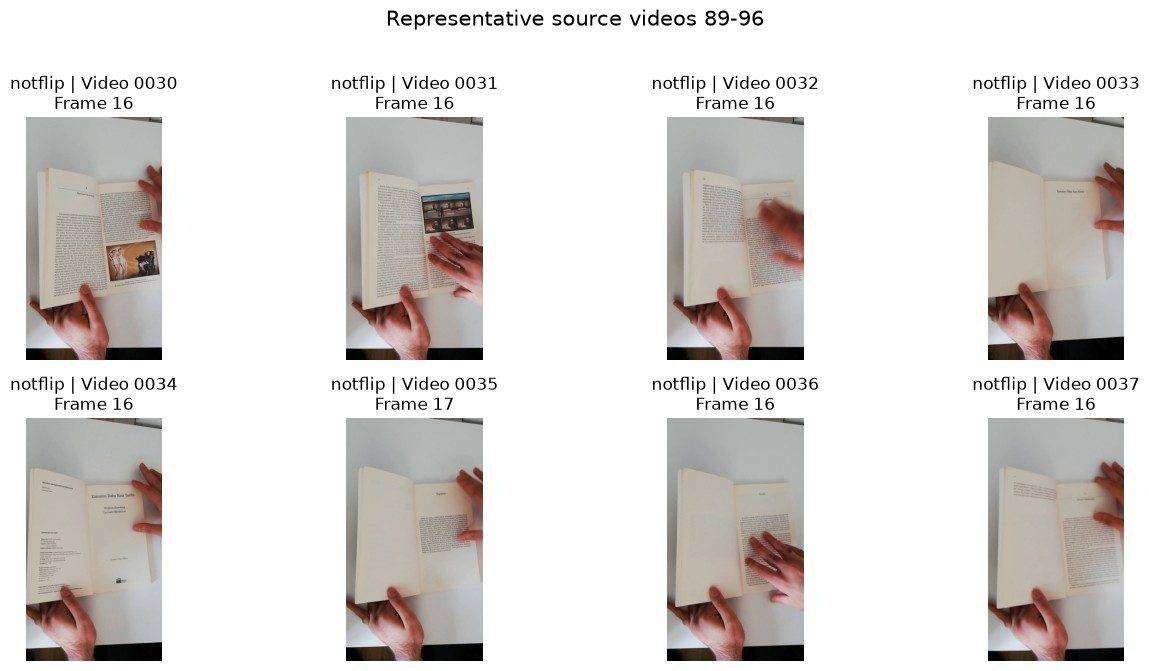

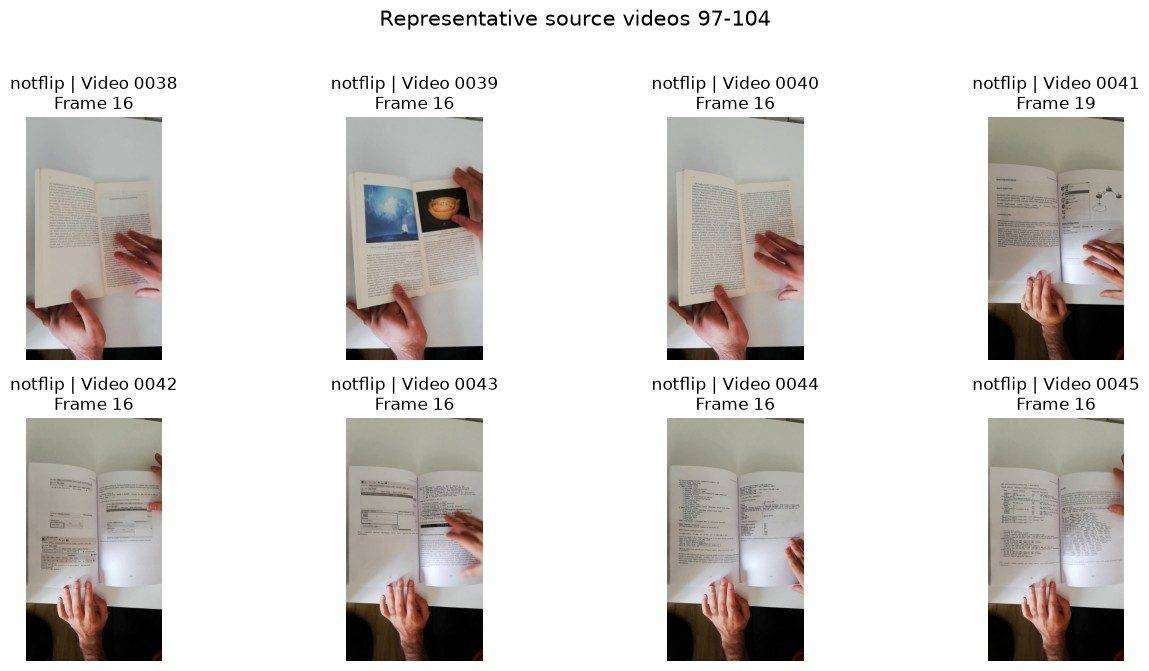

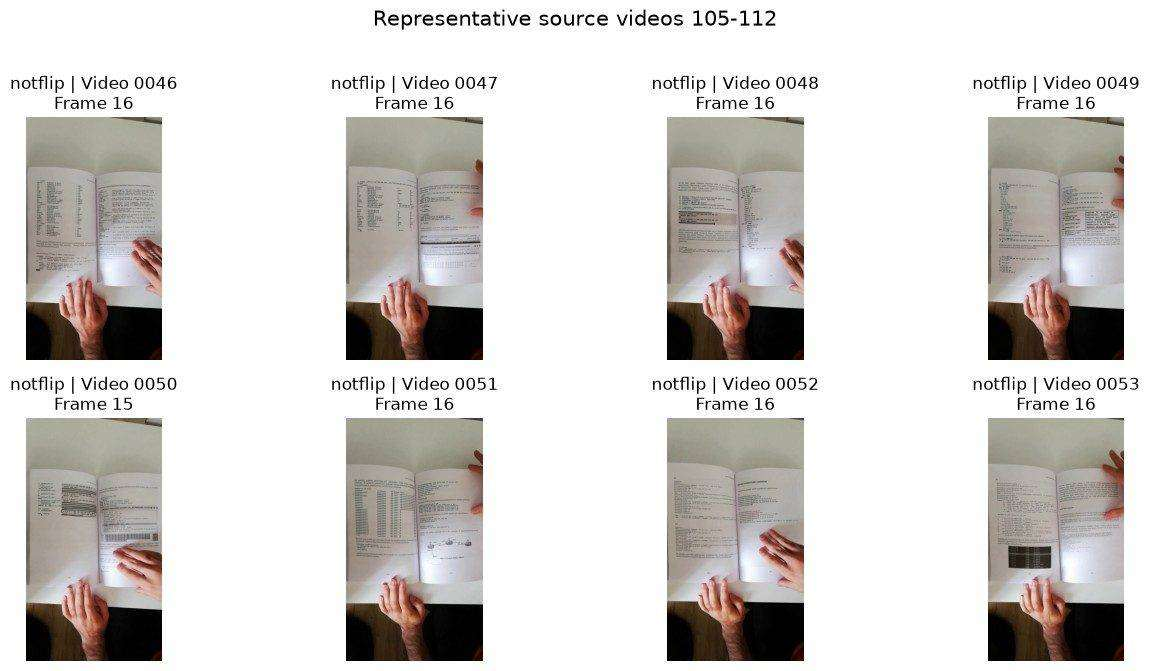

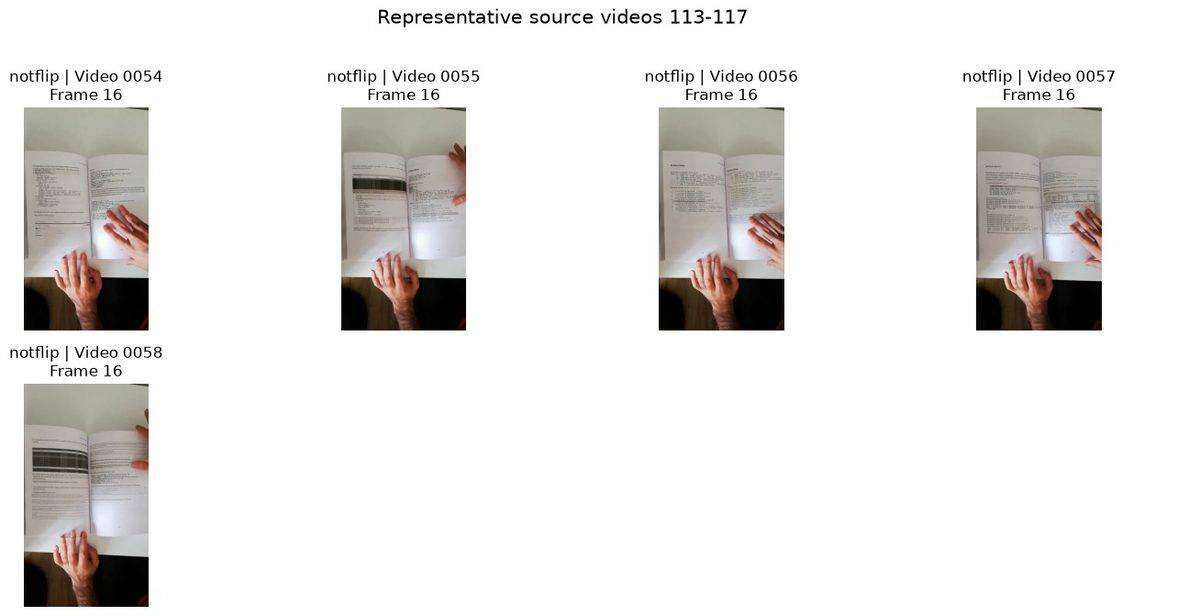

</details>

## Data-audit conclusion

The audit supported three important modelling decisions:

1. **Source identity matters.** Adjacent frames from one video are not independent observations.
2. **Temporal ordering matters.** Later frames can differ from early frames even within a known source.
3. **Evaluation design matters.** Near-random frame partitions can substantially overstate robustness if correlated frames or source identities appear on both sides of the split.

Notebook 2 therefore evaluates scratch-CNN selection under the four frozen historical regimes rather than relying on a single supplied split.